# Signature controls for LQ stochastic control under partial information

This notebook implements the note *"Signature methods to optimal controls", §1: LQ stochastic control under partial information*.

**Problem.** A hidden state $X$ is observed only through a noisy observation $Y$:
$$dX^u_t=(b_0+b_1X^u_t+b_2u_t)\,dt+dB_t,\qquad dY^u_t=(c_0+c_1X^u_t)\,dt+dW_t,\qquad B\perp W,$$
$$J(u)=\mathbb E\Big[\int_0^T\big\{A(t)(X^u_t)^2+B(t)u_t^2+2C(t)X^u_t+2D(t)u_t\big\}dt+E\,(X^u_T)^2+2G\,X^u_T\Big],$$
with polynomial weights $A(t)=\sum_m\frac{t^m}{m!}A_m$ (likewise $B,C,D$). The control may only use the observations, so we take signature controls of $Y$:
$$u_t=\langle\mathtt u,\widehat{\mathbb Y}^u_t\rangle,\qquad \mathtt u\in T^M((\mathbb R^2)^*),$$
where $\widehat{\mathbb Y}^u$ is the signature of $(t,Y^u)$.

**The note's approach.** Everything is rewritten as linear functionals of $\widehat{\mathbb W}=\mathrm{Sig}((\cdot,B_\cdot,W_\cdot))$: $u_t=\langle\tilde{\mathtt u},\widehat{\mathbb W}_t\rangle$, $X^u=\langle\mathtt X^{\tilde{\mathtt u}},\widehat{\mathbb W}\rangle$, $Y^u=\langle\mathtt Y^{\tilde{\mathtt u}},\widehat{\mathbb W}\rangle$, and $(\widehat{\mathbb Y}^u_t)^{\mathbf v}=\langle\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v),\widehat{\mathbb W}_t\rangle$.
These tensors are solved for level by level. The truncated cost $J^{\rm L_1,L_2}(\mathtt u)=\langle\mathtt J^{\rm L_1,L_2}(\mathtt u),\mathbb E[\widehat{\mathbb W}_T]\rangle$ is then a polynomial in the coefficients of $\mathtt u$, but no longer a quadratic one.

**Prompts and where they are answered.**

| Prompt | Section |
|---|---|
| 1. Implement the note as for the arXiv paper | §1–§4, with checks in §6 |
| 2. Coefficients of the proxy polynomial, numerical minimisation (SGD, Adam, or else) | §7 |
| 3. Several $\mathrm L_1,\mathrm L_2,M$, benchmarked against the HJB solution in partial information | §5 (benchmark), §8 |
| 4. Sample paths of the controls with the benchmark: hidden state, observation, control | §9 |

**Reuse.** The tensor layout, the shuffle and pairing-matrix machinery, the Fawcett expected signature, `CostFunctionals` and `signature_stream` are copied unchanged from `lq_signature_control_multidim.ipynb` (next cell). The notebook needs only `numpy`, `scipy` and `matplotlib`.

In [1]:
import numpy as np, itertools, time, gc
from math import factorial, comb
from dataclasses import dataclass
import matplotlib.pyplot as plt
np.set_printoptions(precision=5, suppress=True, linewidth=120)

## 0. Toolkit reused from the previous notebook (unchanged)

Flat tensors `[level 0 | level 1 | …]`, row-major within a level, with **0-based letters**. For $\widehat{\mathbb W}$ the letters are `0` = $t$, `1` = $B$, `2` = $W$, i.e. the note's $\mathbf 1,\mathbf 2,\mathbf 3$. For $\widehat{\mathbb Y}$ they are `0` = $t$, `1` = $Y$, i.e. the note's $\mathbf 1,\mathbf 2$. `TensorSpace.word_str` prints words with the note's 1-based letters.

`CostFunctionals(D, T, L, M, m_max)` builds the pairing matrices with $\langle x,G_{\rm run}^{(m)}y\rangle=\langle(\mathbf 1^{\otimes m}⧢x⧢y)\otimes\mathbf 1,\mathbb E\widehat{\mathbb W}_T\rangle$, and so on. Here it is called with $D=2$ noise letters ($B$ and $W$); its arguments $(L,M)$ play the roles of $(\mathrm L_1,\mathrm L_2)$.

In [2]:
class TensorSpace:
    """Truncated tensor algebra T^L(R^d), stored flat: level 0, level 1, ..., level L.
    Word (i1..im) at level m has flat index offset[m] + sum_k i_k d^(m-k)  (row-major)."""
    def __init__(self, d, L):
        self.d, self.L = d, L
        self.sizes = [d**m for m in range(L + 1)]
        self.offsets = np.concatenate([[0], np.cumsum(self.sizes)]).astype(int)
        self.dim = int(self.offsets[-1])
    def sl(self, m):
        return slice(self.offsets[m], self.offsets[m + 1])
    def index(self, word):
        m = len(word); i = 0
        for a in word: i = i * self.d + a
        return int(self.offsets[m] + i)
    def words(self):
        return [w for m in range(self.L + 1) for w in itertools.product(range(self.d), repeat=m)]
    @staticmethod
    def word_str(w):
        return "∅" if len(w) == 0 else "".join(str(a + 1) for a in w)   # paper's letters: 1 = time

def to_levels(x, ts):
    return [x[..., ts.sl(m)] for m in range(ts.L + 1)]

def from_levels(levels):
    return np.concatenate(levels, axis=-1)

def tensor_product_levels(x, y, Lout, d):
    """(x ⊗ y) truncated at Lout; x, y are lists of level arrays (no batch)."""
    out = [np.zeros(d**n) for n in range(Lout + 1)]
    for p, xp in enumerate(x):
        if p > Lout or not np.any(xp): continue
        for q, yq in enumerate(y):
            if p + q > Lout or not np.any(yq): continue
            out[p + q] += np.outer(xp, yq).ravel()
    return out

def expected_signature_bm(D, T, Lmax):
    """E[Ŵ_T] = exp_⊗( T (e_time + 1/2 Σ_d e_d⊗e_d) ), letters: 0 = time, 1..D = W^(1..D)."""
    d = D + 1
    Q = [np.zeros(d**n) for n in range(Lmax + 1)]
    if Lmax >= 1: Q[1][0] = 1.0
    if Lmax >= 2:
        for a in range(1, d): Q[2][a * d + a] = 0.5
    ES = [np.zeros(d**n) for n in range(Lmax + 1)]; ES[0][0] = 1.0
    term = [lv.copy() for lv in ES]
    for k in range(1, Lmax + 1):
        term = tensor_product_levels(term, Q, Lmax, d)
        term = [t * (T / k) for t in term]
        ES = [a + b for a, b in zip(ES, term)]
    return ES

_shuffle_cache = {}

def _shuffle_index(p, q, d):
    """For each shuffle (choice of positions of the first word) the output index of (v, w)."""
    key = (p, q, d)
    if key in _shuffle_cache: return _shuffle_cache[key]
    n = p + q
    vdig = np.array(list(itertools.product(range(d), repeat=p)), dtype=np.int64).reshape(d**p, p)
    wdig = np.array(list(itertools.product(range(d), repeat=q)), dtype=np.int64).reshape(d**q, q)
    idx = []
    for pos in itertools.combinations(range(n), p):
        rest = [i for i in range(n) if i not in pos]
        vc = (vdig * (d ** (n - 1 - np.array(pos, dtype=np.int64)))).sum(1) if p else np.zeros(1, np.int64)
        wc = (wdig * (d ** (n - 1 - np.array(rest, dtype=np.int64)))).sum(1) if q else np.zeros(1, np.int64)
        idx.append((vc[:, None] + wc[None, :]).ravel())
    _shuffle_cache[key] = idx
    return idx

def shuffle_levels(xp, yq, p, q, d):
    out = np.zeros(d ** (p + q))
    prod = np.outer(xp, yq).ravel()
    for idx in _shuffle_index(p, q, d):
        np.add.at(out, idx, prod)
    return out

def shuffle_product(x, y, Lout, d):
    """x ш y truncated at Lout; x, y lists of level arrays."""
    out = [np.zeros(d**n) for n in range(Lout + 1)]
    for p, xp in enumerate(x):
        if not np.any(xp): continue
        for q, yq in enumerate(y):
            if p + q > Lout or not np.any(yq): continue
            out[p + q] += shuffle_levels(xp, yq, p, q, d)
    return out

def shuffle_pair_matrix(g, p, q, d):
    """g: (B, d^(p+q)).  Returns M (B, d^p, d^q) with M[b, v, w] = <v ш w, g_b>.
    Recursion  <va ш wb, g> = <v ш wb, g|a> + <va ш w, g|b>,  g|c[u] := g[uc],
    evaluated by dynamic programming over (|v|, |w|), one anti-diagonal at a time."""
    g = np.atleast_2d(g); B0 = g.shape[0]; n = p + q
    # stripped[k] has batch index (b, a1, ..., ak) with a1 the last stripped letter
    stripped = [g]
    for k in range(n):
        x = stripped[-1]
        stripped.append(x.reshape(x.shape[0], d ** (n - k - 1), d).transpose(0, 2, 1)
                         .reshape(x.shape[0] * d, d ** (n - k - 1)))
    prev = {}
    for s in range(0, n + 1):                       # s = pp + qq
        gk = stripped[n - s]; Bk = gk.shape[0]; cur = {}
        for pp in range(max(0, s - q), min(p, s) + 1):
            qq = s - pp
            if pp == 0:   cur[(pp, qq)] = gk.reshape(Bk, 1, d**qq); continue
            if qq == 0:   cur[(pp, qq)] = gk.reshape(Bk, d**pp, 1); continue
            T1 = prev[(pp - 1, qq)].reshape(Bk, d, d**(pp - 1), d**qq).transpose(0, 2, 1, 3).reshape(Bk, d**pp, d**qq)
            T2 = prev[(pp, qq - 1)].reshape(Bk, d, d**pp, d**(qq - 1)).transpose(0, 2, 3, 1).reshape(Bk, d**pp, d**qq)
            cur[(pp, qq)] = T1 + T2
        prev = cur
    return prev[(p, q)]

def pairing_matrix(g_levels, Lr, Lc, d):
    """G[v, w] = <v ш w, g> for all words |v| <= Lr, |w| <= Lc (flat layout)."""
    tr, tc = TensorSpace(d, Lr), TensorSpace(d, Lc)
    G = np.zeros((tr.dim, tc.dim))
    for p in range(Lr + 1):
        for q in range(Lc + 1):
            G[tr.sl(p), tc.sl(q)] = shuffle_pair_matrix(g_levels[p + q][None], p, q, d)[0]
    return G

def running_functional(ES, m, Lmax, d):
    """Γ^(m) with  <u, Γ^(m)> = <(1^{⊗m} ш u) ⊗ 1, E[Ŵ_T]> = E ∫_0^T t^m/m! <u, Ŵ_t> dt   (levels 0..Lmax)."""
    out = []
    for n in range(Lmax + 1):
        h = ES[m + n + 1].reshape(d ** (m + n), d)[:, 0]        # strip final time letter
        out.append(shuffle_pair_matrix(h[None], m, n, d)[0, 0, :])   # row of word 1^{⊗m} (index 0)
    return out

class CostFunctionals:
    """Pairing matrices / vectors such that, for tensors x, y,
       x @ Grun[m] @ y = <(1^{⊗m} ш x ш y) ⊗ 1, E[Ŵ_T]>,   lrun[m] @ x = <(1^{⊗m} ш x) ⊗ 1, E[Ŵ_T]>,
       x @ Gterm  @ y = <x ш y, E[Ŵ_T]>,                    lterm  @ x = <x, E[Ŵ_T]>."""
    def __init__(self, D, T, L, M, m_max, ES=None):
        d = D + 1; Lb = max(L, M); self.d, self.L, self.M = d, L, M
        need = 2 * Lb + m_max + 1
        self.ES = expected_signature_bm(D, T, need) if ES is None else ES[:need + 1]
        self.Gamma = [running_functional(self.ES, m, 2 * Lb, d) for m in range(m_max + 1)]
        self.Grun  = [pairing_matrix(Gm, L, L, d) for Gm in self.Gamma]
        self.GrunU = [pairing_matrix(Gm, M, M, d) for Gm in self.Gamma]
        self.Gterm = pairing_matrix(self.ES, L, L, d)
        self.lrun  = [from_levels(Gm[:L + 1]) for Gm in self.Gamma]
        self.lrunU = [from_levels(Gm[:M + 1]) for Gm in self.Gamma]
        self.lterm = from_levels(self.ES[:L + 1])

def signature_stream(dW, dt, Lsig):
    """Yield the flat signature of the time-augmented piecewise-linear path at t_0, t_1, ..., t_n.
    dW: (n_paths, n_steps, D).  Chen's identity S_{t+dt} = S_t ⊗ exp(Δ), evaluated level by level with a
    Horner scheme:  (S ⊗ e^Δ)_m = S_m + (((S_0 Δ/m + S_1) Δ/(m-1) + S_2) Δ/(m-2) + ... + S_{m-1}) Δ/1."""
    n, steps, D = dW.shape; d = D + 1
    S = [np.ones((n, 1))] + [np.zeros((n, d**m)) for m in range(1, Lsig + 1)]
    yield np.concatenate(S, axis=1)
    for i in range(steps):
        inc = np.concatenate([np.full((n, 1), dt), dW[:, i, :]], axis=1)
        new = [S[0]]
        for m in range(1, Lsig + 1):
            acc = S[0] * inc / m
            for j in range(1, m):
                acc = ((acc + S[j])[:, :, None] * inc[:, None, :]).reshape(n, -1) / (m - j)
            new.append(S[m] + acc)
        S = new
        yield np.concatenate(S, axis=1)

def mean_ci(x):
    return x.mean(), 1.96 * x.std(ddof=1) / np.sqrt(len(x))

## 1. The model and the tensor equations

From the note, with $\phi$ the empty word:
$$\mathtt X^{\tilde{\mathtt u}}=X_0\,\phi+(b_0\phi+b_1\mathtt X^{\tilde{\mathtt u}}+b_2\tilde{\mathtt u})\otimes\mathbf 1+\mathbf 2,\qquad
\mathtt Y^{\tilde{\mathtt u}}=Y_0\,\phi+(c_0\phi+c_1\mathtt X^{\tilde{\mathtt u}})\otimes\mathbf 1+\mathbf 3,$$
$$\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\phi)=\phi,\quad \tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v\mathbf 1)=\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v)\otimes\mathbf 1,\quad
\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v\mathbf 2)=\big(\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v)⧢(c_0\phi+c_1\mathtt X^{\tilde{\mathtt u}})\big)\otimes\mathbf 1+\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v)\otimes\mathbf 3,$$
$$\tilde{\mathtt u}=\sum_{m=0}^M\sum_{\mathbf v\in\{\mathbf 1,\mathbf 2\}^m}\mathtt u^{\mathbf v}\,\tilde{\mathtt Y}^{\tilde{\mathtt u}}(\mathbf v).$$
The rule for $\mathbf v\mathbf 2$ is $d\widehat{\mathbb Y}^{\mathbf v\mathbf 2}_t=\widehat{\mathbb Y}^{\mathbf v}_t\circ dY_t=\widehat{\mathbb Y}^{\mathbf v}_t(c_0+c_1X_t)\,dt+\widehat{\mathbb Y}^{\mathbf v}_t\circ dW_t$. The product $\widehat{\mathbb Y}^{\mathbf v}X$ is a shuffle of tensors, and all integrals are Stratonovich, like $\widehat{\mathbb W}$ itself.

The unknowns are the coefficients $\theta=(\mathtt u^{\mathbf v})_{|\mathbf v|\le M}$, so $P=2^{M+1}-1$ numbers, ordered as `TensorSpace(2, M).words()`.

In [3]:
@dataclass
class PartialLQModel:
    """1-D LQ problem under partial information (notation of the note):
         dX = (b0 + b1 X + b2 u) dt + dB,     dY = (c0 + c1 X) dt + dW,     B ⟂ W,
         J(u) = E[ ∫ A(t) X² + B(t) u² + 2 C(t) X + 2 D(t) u dt + E X_T² + 2 G X_T ],
       A(t) = Σ_m t^m/m! A[m] (same for B, C, D).  Driving signature: Ŵ = Sig(t, B, W), letters 0 = t, 1 = B, 2 = W.
       Observation signature: Ŷ = Sig(t, Y), letters 0 = t, 1 = Y."""
    T: float = 1.0
    X0: float = 1.0; Y0: float = 0.0
    b0: float = 0.0; b1: float = 0.0; b2: float = 1.0
    c0: float = 0.0; c1: float = 1.0
    A: tuple = (1.0,); B: tuple = (1.0,); C: tuple = (0.0,); D: tuple = (0.0,)
    E: float = 1.0; G: float = 0.0
    d = 3; dY = 2                                      # alphabet sizes of Ŵ and Ŷ
    @property
    def m_max(self):
        return max(len(self.A), len(self.B), len(self.C), len(self.D)) - 1
    @staticmethod
    def poly(coefs, t):
        return sum(np.asarray(t, float) ** m / factorial(m) * c for m, c in enumerate(coefs))

## 2. Tensors whose coefficients are polynomials in $\theta$

The system is **nonlinear in $\theta$**. $\tilde{\mathtt u}$ multiplies $\theta$ by $\tilde{\mathtt Y}(\mathbf v)$; this depends on $\mathtt X$ through the shuffle, and $\mathtt X$ depends on $\tilde{\mathtt u}$.
Every truncated tensor is therefore a polynomial in $\theta$ with tensor coefficients, $\sum_\alpha\theta^\alpha\,T_\alpha$. These are stored level by level (`PolyLevel`, `PolyTensor`).

* **Monomials.** A monomial $\theta^\alpha$ is encoded as one `int64` with one bit field per variable. Then $\theta^\alpha\theta^\beta$ corresponds to `code(α) + code(β)`, so products of polynomials are additions of integer arrays. Total degrees are tracked, and a check guards the bit fields against overflow.
* **Shuffles.** `poly_shuffle` forms the shuffle for every pair of monomials at once, using the shuffle index maps `_shuffle_index` from the previous notebook. A fixed interleaving maps $(\mathbf v,\mathbf w)$ to an output word injectively, so each index map is applied with one vectorised update.
* **Exact derivatives.** `monomials(…, jac=True)` returns $\theta^\alpha$ and $\partial_\theta\theta^\alpha$ exactly, using prefix and suffix products, so $\theta_i=0$ needs no special case.

In [4]:
class MonomialCoder:
    """θ^α encoded as one int64: α_i stored in a bit field of width `bits`, so θ^α θ^β ↔ code(α) + code(β).
    Valid while every exponent < 2^bits; we track total degrees and check them (exponent ≤ total degree)."""
    def __init__(self, P):
        self.P = P; self.bits = max(1, 62 // P); self.base = 1 << self.bits
        self.unit = np.array([1 << (self.bits * i) for i in range(P)], dtype=np.int64)
    def decode(self, codes):
        codes = np.asarray(codes, dtype=np.int64)
        return (codes[:, None] >> (self.bits * np.arange(self.P, dtype=np.int64))) & (self.base - 1)
    def check(self, deg):
        if deg.size and deg.max() >= self.base:
            raise OverflowError(f"total degree {deg.max()} ≥ {self.base}: too many variables for the int64 code")


def _merge(codes, deg, coef):
    """Sum rows with equal monomial code; drop rows that are identically zero."""
    if codes.size == 0:
        return codes, deg, coef
    order = np.argsort(codes, kind='stable'); codes, deg, coef = codes[order], deg[order], coef[order]
    start = np.flatnonzero(np.r_[True, codes[1:] != codes[:-1]])
    coef = np.add.reduceat(coef, start, axis=0); codes, deg = codes[start], deg[start]
    keep = np.any(coef != 0.0, axis=1)
    return codes[keep], deg[keep], coef[keep]


class PolyLevel:
    """Level-m component of a θ-polynomial tensor: Σ_k θ^{α_k} coef[k],  coef[k] ∈ (R^d)^{⊗m}."""
    def __init__(self, m, d, codes=None, deg=None, coef=None):
        self.m, self.d = m, d
        self.codes = np.zeros(0, np.int64) if codes is None else np.asarray(codes, np.int64)
        self.deg = np.zeros(0, np.int64) if deg is None else np.asarray(deg, np.int64)
        self.coef = np.zeros((0, d ** m)) if coef is None else np.asarray(coef, float).reshape(-1, d ** m)
    @classmethod
    def constant(cls, m, d, arr):
        return cls(m, d, [0], [0], np.asarray(arr, float).reshape(1, -1))
    @property
    def n(self):
        return self.codes.size
    def __add__(self, other):
        if self.n == 0: return other
        if other.n == 0: return self
        return PolyLevel(self.m, self.d, *_merge(np.r_[self.codes, other.codes], np.r_[self.deg, other.deg],
                                                 np.vstack([self.coef, other.coef])))
    def scale(self, c):
        return PolyLevel(self.m, self.d, self.codes, self.deg, self.coef * c) if c != 0 else PolyLevel(self.m, self.d)
    def times_var(self, coder, i):
        """θ_i × (this)."""
        return PolyLevel(self.m, self.d, self.codes + coder.unit[i], self.deg + 1, self.coef)
    def concat(self, j):
        """(this) ⊗ letter j."""
        out = np.zeros((self.n, self.d ** self.m, self.d)); out[:, :, j] = self.coef
        return PolyLevel(self.m + 1, self.d, self.codes, self.deg, out.reshape(self.n, self.d ** (self.m + 1)))
    def eval(self, coder, theta):
        """Numeric tensor at θ."""
        if self.n == 0: return np.zeros(self.d ** self.m)
        return monomials(coder, self.codes, theta) @ self.coef


def poly_shuffle(x, y, coder, chunk=4_000_000):
    """x ш y for θ-polynomial levels x (level p) and y (level q): every pair of monomials, vectorised
    with the shuffle index maps of the previous notebook (_shuffle_index), then monomials are merged."""
    p, q, d = x.m, y.m, x.d
    if x.n == 0 or y.n == 0: return PolyLevel(p + q, d)
    idx_list = _shuffle_index(p, q, d)
    codes = (x.codes[:, None] + y.codes[None, :]).ravel(); deg = (x.deg[:, None] + y.deg[None, :]).ravel()
    coder.check(deg)
    out = np.zeros((x.n * y.n, d ** (p + q)))
    rows_per = max(1, chunk // max(1, y.n * d ** (p + q)))
    for a0 in range(0, x.n, rows_per):
        xa = x.coef[a0:a0 + rows_per]
        prod = (xa[:, None, :, None] * y.coef[None, :, None, :]).reshape(-1, d ** p * d ** q)
        blk = out[a0 * y.n:(a0 + xa.shape[0]) * y.n]
        for idx in idx_list:                       # a fixed interleaving is injective: no repeated indices
            blk[:, idx] += prod
    return PolyLevel(p + q, d, *_merge(codes, deg, out))


def monomials(coder, codes, theta, jac=False):
    """θ^α for each code (and, optionally, the Jacobian ∂θ^α/∂θ)."""
    E = coder.decode(codes); theta = np.asarray(theta, float)
    Pw = theta[None, :] ** E
    val = Pw.prod(1)
    if not jac: return val
    # exclusive products via prefix/suffix (no division, so θ_i = 0 is fine)
    pre = np.cumprod(np.c_[np.ones(len(E)), Pw[:, :-1]], axis=1)          # Π_{j<i} Pw[:, j]
    suf = np.ones_like(Pw)                                                # Π_{j>i} Pw[:, j]
    for i in range(Pw.shape[1] - 2, -1, -1): suf[:, i] = suf[:, i + 1] * Pw[:, i + 1]
    dPw = np.where(E > 0, E * theta[None, :] ** np.maximum(E - 1, 0), 0.0)
    return val, dPw * pre * suf


class PolyTensor:
    """θ-polynomial tensor in T^L(R^d), stored level by level."""
    def __init__(self, L, d):
        self.L, self.d = L, d; self.levels = [PolyLevel(m, d) for m in range(L + 1)]
    def flat(self, L=None):
        """(codes, deg, coef (n, dim T^L)) with all levels ≤ L merged on a common monomial list."""
        L = self.L if L is None else L; ts = TensorSpace(self.d, L)
        cs = [lv.codes for lv in self.levels[:L + 1] if lv.n]
        if not cs: return np.zeros(0, np.int64), np.zeros(0, np.int64), np.zeros((0, ts.dim))
        codes, inv = np.unique(np.concatenate(cs), return_inverse=True)
        deg = np.zeros(codes.size, np.int64); coef = np.zeros((codes.size, ts.dim)); k = 0
        for m, lv in enumerate(self.levels[:L + 1]):
            if lv.n == 0: continue
            r = inv[k:k + lv.n]; k += lv.n
            coef[r, ts.sl(m)] = lv.coef; deg[r] = lv.deg
        return codes, deg, coef
    def eval(self, coder, theta, L=None):
        codes, _, coef = self.flat(L)
        return monomials(coder, codes, theta) @ coef if codes.size else np.zeros(TensorSpace(self.d, self.L if L is None else L).dim)
    def n_monomials(self):
        return [lv.n for lv in self.levels]

## 3. Level-by-level solution (the note's recursion)

Every right-hand side raises the tensor level by one ($\otimes\mathbf 1$ or $\otimes\mathbf 3$), or is the constant $\mathbf 2$ or $\mathbf 3$. So level $\ell$ of each unknown depends only on levels $<\ell$; the only exception is $\tilde{\mathtt u}$, which uses the level-$\ell$ values of $\tilde{\mathtt Y}(\mathbf v)$ computed just before it. This is the note's iteration:
$$\mathrm{Proj}_{\rm L+1}(\mathtt X)=\mathrm{Proj}_{\rm L+1}\big((b_0\phi+b_1\mathrm{Proj}_{\rm L}\mathtt X+b_2\mathrm{Proj}_{\rm L}\tilde{\mathtt u})\otimes\mathbf 1+\mathbf 2\big),\ \dots,\ \mathrm{Proj}_{\rm L+1}(\tilde{\mathtt u})=\sum_{\mathbf v}\mathtt u^{\mathbf v}\mathrm{Proj}_{\rm L+1}(\tilde{\mathtt Y}(\mathbf v)).$$
`solve_tensors` computes only the new level at each step. $\tilde{\mathtt Y}(\mathbf v)$ vanishes below level $|\mathbf v|$, so the shuffle sum starts there. This is the observation $\tilde{\mathtt Y}(\mathbf v)^{\mathbf w}=0$ for $|\mathbf v|>|\mathbf w|$ in the note.

**Degree structure.** Going once round the loop $X\to Y\to u\to X$ costs two levels: one $\otimes\mathbf 1$ in the drift of $Y$ and one in the drift of $X$. So the $\theta$-degree of level $\ell$ of $\mathtt X$ grows only like $\lceil\ell/2\rceil$, and the polynomials stay small. The cell below prints the number of monomials per level.

In [5]:
def y_words(M):
    """Words over the observation alphabet {0 = t, 1 = Y}, ordered by length (the coordinates of θ)."""
    return TensorSpace(2, M).words()


def solve_tensors(model, M, Lmax, verbose=False):
    """Level-by-level solution of
         X̃ = X0 ∅ + (b0 ∅ + b1 X̃ + b2 ũ) ⊗ 1 + 2 ,          Ỹ = Y0 ∅ + (c0 ∅ + c1 X̃) ⊗ 1 + 3 ,
         Ỹ(∅) = ∅,  Ỹ(v1) = Ỹ(v) ⊗ 1,  Ỹ(v2) = (Ỹ(v) ш (c0 ∅ + c1 X̃)) ⊗ 1 + Ỹ(v) ⊗ 3,
         ũ = Σ_{|v| ≤ M} θ_v Ỹ(v),
    as polynomials in θ = (u^v)_{|v| ≤ M}.  (0-based letters of Ŵ: 0 = t, 1 = B, 2 = W.)
    Level ℓ+1 of every unknown only needs levels ≤ ℓ (Ỹ before ũ within a level), as in the note."""
    d = model.d; words = y_words(M); P = len(words); coder = MonomialCoder(P)
    widx = {w: i for i, w in enumerate(words)}
    X, U, Yobs = PolyTensor(Lmax, d), PolyTensor(Lmax, d), PolyTensor(Lmax, d)
    Yt = {w: PolyTensor(Lmax, d) for w in words}
    X.levels[0] = PolyLevel.constant(0, d, [model.X0]); Yobs.levels[0] = PolyLevel.constant(0, d, [model.Y0])
    Yt[()].levels[0] = PolyLevel.constant(0, d, [1.0])
    U.levels[0] = Yt[()].levels[0].times_var(coder, widx[()])                    # ũ^∅ = u^∅
    eB, eW = np.eye(d)[1], np.eye(d)[2]
    t0 = time.perf_counter()
    for l in range(1, Lmax + 1):
        # Z_b = (c0 ∅ + c1 X̃) at level b
        Z = [X.levels[b].scale(model.c1) for b in range(l)]
        Z[0] = Z[0] + PolyLevel.constant(0, d, [model.c0])
        # X̃ and Ỹ (the observation itself)
        drift = X.levels[l - 1].scale(model.b1) + U.levels[l - 1].scale(model.b2)
        if l == 1: drift = drift + PolyLevel.constant(0, d, [model.b0])
        X.levels[l] = drift.concat(0) + (PolyLevel.constant(1, d, eB) if l == 1 else PolyLevel(l, d))
        Yobs.levels[l] = Z[l - 1].concat(0) + (PolyLevel.constant(1, d, eW) if l == 1 else PolyLevel(l, d))
        # Ỹ(v) for all |v| ≤ M
        for w in words:
            if len(w) == 0 or len(w) > l: continue
            v, last = w[:-1], w[-1]
            if last == 0:
                Yt[w].levels[l] = Yt[v].levels[l - 1].concat(0)
            else:
                acc = Yt[v].levels[l - 1].concat(2)                               # Ỹ(v) ⊗ 3
                for a in range(len(v), l):                                         # Ỹ(v) vanishes below level |v|
                    sh = poly_shuffle(Yt[v].levels[a], Z[l - 1 - a], coder)
                    acc = acc + sh.concat(0)
                Yt[w].levels[l] = acc
        # ũ at level l
        acc = PolyLevel(l, d)
        for w in words:
            if len(w) <= l and Yt[w].levels[l].n:
                acc = acc + Yt[w].levels[l].times_var(coder, widx[w])
        U.levels[l] = acc
        if verbose:
            print(f"  level {l}: #monomials X̃ {X.levels[l].n:6d}, ũ {U.levels[l].n:6d}, "
                  f"max deg ũ {U.levels[l].deg.max() if U.levels[l].n else 0:2d}   ({time.perf_counter() - t0:.1f}s)")
    return dict(X=X, U=U, Yobs=Yobs, Yt=Yt, coder=coder, words=words, P=P, M=M, Lmax=Lmax)

In [6]:
m = PartialLQModel(T=1.0, X0=1.0, Y0=0.0, b0=0.0, b1=0.5, b2=1.0, c0=0.0, c1=1.0,
                   A=(1.0,), B=(1.0,), C=(0.0,), D=(0.0,), E=1.0, G=0.0)
t0 = time.perf_counter(); sol = solve_tensors(m, 2, 7, verbose=True)
print(f"M = 2 (P = {sol['P']} coefficients), levels 0..7: {time.perf_counter() - t0:.2f}s")
print("θ coordinates (note's letters 1 = t, 2 = Y):", [TensorSpace.word_str(w) for w in sol['words']])
print("monomials per level:  X̃", sol['X'].n_monomials(), "  ũ", sol['U'].n_monomials())

  level 1: #monomials X̃      2, ũ      2, max deg ũ  1   (0.0s)
  level 2: #monomials X̃      4, ũ      6, max deg ũ  2   (0.0s)
  level 3: #monomials X̃      9, ũ     10, max deg ũ  2   (0.0s)
  level 4: #monomials X̃     14, ũ     19, max deg ũ  3   (0.0s)
  level 5: #monomials X̃     23, ũ     34, max deg ũ  3   (0.0s)
  level 6: #monomials X̃     38, ũ     51, max deg ũ  4   (0.0s)
  level 7: #monomials X̃     55, ũ     76, max deg ũ  4   (0.1s)
M = 2 (P = 7 coefficients), levels 0..7: 0.11s
θ coordinates (note's letters 1 = t, 2 = Y): ['∅', '1', '2', '11', '12', '21', '22']
monomials per level:  X̃ [1, 2, 4, 9, 14, 23, 38, 55]   ũ [1, 2, 6, 10, 19, 34, 51, 76]


## 4. The proxy cost $J^{\rm L_1,L_2}$ as an explicit polynomial

From the note,
$$\mathtt J(\mathtt u)=\big(\mathtt A⧢\mathtt X⧢\mathtt X+\mathtt B⧢\tilde{\mathtt u}⧢\tilde{\mathtt u}+2\,\mathtt C⧢\mathtt X+2\,\mathtt D⧢\tilde{\mathtt u}\big)\otimes\mathbf 1+E\,\mathtt X⧢\mathtt X+2G\,\mathtt X,
\qquad J^{\rm L_1,L_2}(\mathtt u)=\langle\mathtt J^{\rm L_1,L_2}(\mathtt u),\mathbb E[\widehat{\mathbb W}_T]\rangle,$$
where $\mathtt X$ is truncated at $\mathrm L_1$ and $\tilde{\mathtt u}$ at $\mathrm L_2$.

**Truncation convention.** We solve the recursion up to $\max(\mathrm L_1,\mathrm L_2)$ and truncate afterwards. $\mathtt X^{\le\rm L_1}$ is exact: it only needs $\tilde{\mathtt u}^{\le\rm L_1-1}$. The truncation of $\tilde{\mathtt u}$ only enters the control-cost terms $B$ and $D$.

**Assembly.** Write $\mathtt X^{\le\rm L_1}=\sum_\alpha\theta^\alpha\mathtt X_\alpha$. Each term is then a pairing-matrix product, for example
$\sum_{\alpha,\beta}\theta^{\alpha+\beta}\,A_m\,\mathtt X_\alpha^\top G^{(m)}_{\rm run}\mathtt X_\beta$, with the pairing matrices of the previous notebook. `proxy_cost` returns the polynomial as a `SparsePoly` (coefficients and exponent vectors), with exact value, gradient and Hessian.

In [7]:
class SparsePoly:
    """f(θ) = Σ_k c_k θ^{α_k}, with exact value / gradient / Hessian."""
    def __init__(self, coder, codes, coefs):
        codes, deg, coefs = _merge(np.asarray(codes, np.int64), np.zeros(len(codes), np.int64),
                                   np.asarray(coefs, float).reshape(-1, 1))
        self.coder, self.codes, self.c = coder, codes, coefs[:, 0]
        self.E = coder.decode(codes); self.P = coder.P
    @property
    def degree(self):
        return int(self.E.sum(1).max()) if self.codes.size else 0
    def __call__(self, theta):
        return float(self.c @ np.prod(np.asarray(theta, float)[None, :] ** self.E, axis=1))
    def grad(self, theta):
        _, J = monomials(self.coder, self.codes, theta, jac=True)
        return self.c @ J
    def hess(self, theta):
        theta = np.asarray(theta, float); P = self.P; H = np.zeros((P, P))
        for i in range(P):
            Ei = self.E[:, i]; mask = Ei > 0
            if not mask.any(): continue
            E2 = self.E[mask].copy(); E2[:, i] -= 1
            sub = SparsePoly.__new__(SparsePoly); sub.coder, sub.P = self.coder, P
            sub.E = E2; sub.c = self.c[mask] * Ei[mask]
            sub.codes = (E2 * self.coder.unit[None, :]).sum(1)
            H[i] = sub.grad(theta)
        return 0.5 * (H + H.T)
    def terms(self, top=10):
        """The `top` terms of largest |coefficient|, as (coefficient, exponent vector)."""
        o = np.argsort(-np.abs(self.c))[:top]
        return [(self.c[k], tuple(int(e) for e in self.E[k])) for k in o]


def proxy_cost(model, sol, L1, L2, F=None):
    """J^{L1,L2}(θ) = < (A ш X̃ ш X̃ + B ш ũ ш ũ + 2 C ш X̃ + 2 D ш ũ) ⊗ 1 + E X̃ ш X̃ + 2 G X̃ ,  E[Ŵ_T] >
    with X̃ truncated at L1 and ũ at L2, as an explicit sparse polynomial in θ.  The pairings use the
    CostFunctionals matrices of the previous notebook (Ŵ has D = 2 noise letters: B and W)."""
    F = CostFunctionals(2, model.T, L1, L2, model.m_max) if F is None else F
    assert F.L == L1 and F.M == L2
    coder = sol['coder']
    cx, dx, CX = sol['X'].flat(L1); cu, du, CU = sol['U'].flat(L2)
    codes, coefs = [], []
    def quad(c1, C1, G, w):
        Q = (C1 @ G @ C1.T) * w
        codes.append((c1[:, None] + c1[None, :]).ravel()); coefs.append(Q.ravel())
        coder.check((np.add.outer(dx if C1 is CX else du, dx if C1 is CX else du)).ravel())
    def lin(c1, C1, l, w):
        codes.append(c1); coefs.append((C1 @ l) * w)
    for m in range(model.m_max + 1):
        if m < len(model.A) and model.A[m]: quad(cx, CX, F.Grun[m], model.A[m])
        if m < len(model.B) and model.B[m]: quad(cu, CU, F.GrunU[m], model.B[m])
        if m < len(model.C) and model.C[m]: lin(cx, CX, F.lrun[m], 2 * model.C[m])
        if m < len(model.D) and model.D[m]: lin(cu, CU, F.lrunU[m], 2 * model.D[m])
    if model.E: quad(cx, CX, F.Gterm, model.E)
    if model.G: lin(cx, CX, F.lterm, 2 * model.G)
    return SparsePoly(coder, np.concatenate(codes), np.concatenate(coefs))

## 5. Benchmark: the HJB solution in partial information (separation principle)

For LQ problems with Gaussian noise, the optimal control among $\mathbb F^Y$-adapted controls is certainty-equivalent:
$$u^*_t=-B(t)^{-1}\big(D(t)+b_2(P_t\hat X_t+r_t)\big),\qquad \hat X_t=\mathbb E[X_t\mid\mathcal F^Y_t].$$
$\hat X$ is the Kalman–Bucy filter,
$$d\hat X=(b_0+b_1\hat X+b_2u)\,dt+\Sigma_tc_1\big(dY-(c_0+c_1\hat X)dt\big),\qquad \dot\Sigma=2b_1\Sigma+1-c_1^2\Sigma^2,\quad\Sigma_0=0$$
($X_0$ is known). $P$ and $r$ solve the full-information Riccati equations. The HJB equation is solved on the filter: $\hat X$ is a fully observed linear state driven by the innovation Brownian motion with volatility $K_t=c_1\Sigma_t$.
The estimation error $X-\hat X$ is independent of $\mathcal F^Y$, so
$$J^*=P_0X_0^2+2r_0X_0+s_0+\int_0^TA(t)\Sigma_t\,dt+E\,\Sigma_T .$$
The full-information value, where $X$ is observed, is also returned as a lower bound.

In [8]:
def kalman_riccati_benchmark(model, n_grid=2001, Sigma0=0.0):
    """Optimal partial-information control  u* = -B^{-1}(D + b2 (P X̂ + r)),  X̂ = E[X | F^Y] (Kalman–Bucy):
         dX̂ = (b0 + b1 X̂ + b2 u) dt + K (dY - (c0 + c1 X̂) dt),   K = c1 Σ,   Σ' = 2 b1 Σ + 1 - c1² Σ².
    With the innovation BM ν, X̂ is a fully observed LQ state with noise K dν, hence (X − X̂ ⟂ F^Y)
         J* = P0 X0² + 2 r0 X0 + s0 + ∫ A Σ dt + E Σ_T ,
         -P' = A + 2 b1 P − b2² P² / B,   -r' = C + b1 r + b0 P − b2 P (D + b2 r)/B,
         -s' = 2 b0 r + K² P − (D + b2 r)²/B,   P_T = E, r_T = G, s_T = 0.
    Also returns the full-information value (same P, r; noise 1 instead of K, no Σ terms) as a lower bound."""
    from scipy.integrate import solve_ivp
    m = model
    # forward: Σ and the filtering-error cost ∫ A Σ dt
    sig = solve_ivp(lambda t, z: [2 * m.b1 * z[0] + 1 - m.c1 ** 2 * z[0] ** 2, m.poly(m.A, t) * z[0]], (0, m.T),
                    [Sigma0, 0.0], dense_output=True, rtol=1e-11, atol=1e-12, method='DOP853')
    def rhs(t, y):
        P, r, s, s_full = y
        At, Bt, Ct, Dt = m.poly(m.A, t), m.poly(m.B, t), m.poly(m.C, t), m.poly(m.D, t)
        K = m.c1 * sig.sol(t)[0]; z = Dt + m.b2 * r
        return [-(At + 2 * m.b1 * P - m.b2 ** 2 * P ** 2 / Bt),
                -(Ct + m.b1 * r + m.b0 * P - m.b2 * P * z / Bt),
                -(2 * m.b0 * r + K ** 2 * P - z ** 2 / Bt),
                -(2 * m.b0 * r + P - z ** 2 / Bt)]
    tg = np.linspace(m.T, 0, n_grid)
    sol = solve_ivp(rhs, (m.T, 0), [m.E, m.G, 0.0, 0.0], t_eval=tg, rtol=1e-11, atol=1e-12, method='DOP853')
    t = sol.t[::-1]; P, r, s, s_full = sol.y[:, ::-1]
    Sig = sig.sol(t)[0]
    filt = sig.y[1, -1] + m.E * Sig[-1]
    J = P[0] * m.X0 ** 2 + 2 * r[0] * m.X0 + s[0] + filt
    J_full = P[0] * m.X0 ** 2 + 2 * r[0] * m.X0 + s_full[0]
    return dict(t=t, P=P, r=r, s=s, Sigma=Sig, J=J, J_full=J_full)

**Closed-loop simulation.** We use Euler for $(X,Y)$; both have additive noise, so the Itô and Stratonovich schemes coincide. The control at $t_i$ uses the signature of the observed piecewise-linear $(t,Y)$ path up to $t_i$, updated online by Chen's identity (`chen_step`, the same Horner update as `signature_stream`). The Kalman–Riccati control is simulated with its discrete filter on the same grid.

In [9]:
def chen_step(S, inc):
    """One Chen step S ⊗ exp(inc) on a batch of flat-by-level signatures (list of (n, d^m) arrays), Horner form
    (the same update as signature_stream of the previous notebook, but for increments known only online)."""
    n = inc.shape[0]; new = [S[0]]
    for mlev in range(1, len(S)):
        acc = S[0] * inc / mlev
        for j in range(1, mlev):
            acc = ((acc + S[j])[:, :, None] * inc[:, None, :]).reshape(n, -1) / (mlev - j)
        new.append(S[mlev] + acc)
    return new


def simulate_partial(model, dB, dW, dt, control, kind, M=0, bench=None):
    """Euler scheme for (X, Y) driven by increments dB, dW (n_paths, n_steps), additive noise so Itô = Stratonovich.
    kind = 'signature': control = θ, u_t = <θ, Ŷ_t^{≤M}>, Ŷ the signature of the piecewise-linear (t, Y) path;
    kind = 'kalman':    control ignored, u = optimal Kalman–Riccati feedback of `bench` on the same grid.
    Returns per-path cost and paths of X, Y, u (and the filter X̂ for 'kalman')."""
    m = model; n, steps = dB.shape
    X = np.full(n, float(m.X0)); Y = np.full(n, float(m.Y0)); cost = np.zeros(n)
    Xs, Ys, Us = [X.copy()], [Y.copy()], []
    if kind == 'signature':
        S = [np.ones((n, 1))] + [np.zeros((n, 2 ** k)) for k in range(1, M + 1)]
        th = np.asarray(control, float)
    else:
        Xh = X.copy(); Xhs = [Xh.copy()]
        Kt = m.c1 * bench['Sigma']; P, r = bench['P'], bench['r']
        assert len(P) == steps + 1, "benchmark grid must match the simulation grid"
    for i in range(steps):
        t = i * dt
        At, Bt, Ct, Dt = m.poly(m.A, t), m.poly(m.B, t), m.poly(m.C, t), m.poly(m.D, t)
        if kind == 'signature':
            u = np.concatenate(S, axis=1) @ th
        else:
            u = -(Dt + m.b2 * (P[i] * Xh + r[i])) / Bt
        Us.append(u)
        cost += dt * (At * X ** 2 + Bt * u ** 2 + 2 * Ct * X + 2 * Dt * u)
        dY = (m.c0 + m.c1 * X) * dt + dW[:, i]
        if kind == 'kalman':
            Xh = Xh + (m.b0 + m.b1 * Xh + m.b2 * u) * dt + Kt[i] * (dY - (m.c0 + m.c1 * Xh) * dt); Xhs.append(Xh.copy())
        else:
            S = chen_step(S, np.c_[np.full(n, dt), dY])
        X = X + (m.b0 + m.b1 * X + m.b2 * u) * dt + dB[:, i]
        Y = Y + dY
        Xs.append(X.copy()); Ys.append(Y.copy())
    cost += m.E * X ** 2 + 2 * m.G * X
    out = dict(cost=cost, X=np.array(Xs), Y=np.array(Ys), U=np.array(Us))
    if kind == 'kalman': out['Xhat'] = np.array(Xhs)
    return out

In [10]:
def evaluate_partial(model, controls, n_paths=20000, n_steps=500, seed=0, bench=None):
    """Monte Carlo with common random numbers.  controls: name -> (θ, M).  The Kalman–Riccati control is
    always simulated first on the same (B, W) increments and used as the reference for paired differences
    and the L²(dP⊗dt) distance."""
    rng = np.random.default_rng(seed); dt = model.T / n_steps
    dB = rng.normal(scale=np.sqrt(dt), size=(n_paths, n_steps)); dW = rng.normal(scale=np.sqrt(dt), size=(n_paths, n_steps))
    bench = kalman_riccati_benchmark(model, n_grid=n_steps + 1) if bench is None or len(bench['P']) != n_steps + 1 else bench
    ref = simulate_partial(model, dB, dW, dt, None, 'kalman', bench=bench)
    out = {"u* (Kalman–Riccati)": dict(cost=ref['cost'], diff=np.zeros(n_paths), L2=0.0)}
    for name, (th, M) in controls.items():
        s = simulate_partial(model, dB, dW, dt, th, 'signature', M=M)
        out[name] = dict(cost=s['cost'], diff=s['cost'] - ref['cost'],
                         L2=float(np.sqrt(np.mean(np.sum(dt * (s['U'] - ref['U']) ** 2, axis=0)))))
    return out

## 6. Checks

**(a) Pathwise representation.** Fix some $\theta$ and simulate the closed loop. Then compare $X_t$, $u_t$ and $Y_t$ with $\langle\mathtt X^{\le\rm L}(\theta),\widehat{\mathbb W}_t\rangle$, $\langle\tilde{\mathtt u}^{\le\rm L}(\theta),\widehat{\mathbb W}_t\rangle$ and $\langle\mathtt Y^{\le\rm L}(\theta),\widehat{\mathbb W}_t\rangle$, where $\widehat{\mathbb W}$ is the signature of the same $(t,B,W)$ path. This tests the whole recursion, including the shuffles $\tilde{\mathtt Y}(\mathbf v)⧢\mathtt X$. The errors should fall with $\mathrm L$ to a floor set by the time step.

In [11]:
mchk = PartialLQModel(T=1.0, X0=1.0, Y0=0.3, b0=0.1, b1=0.5, b2=1.0, c0=0.2, c1=1.0)   # all constants switched on
sol_chk = solve_tensors(mchk, 2, 8)
th_chk = np.random.default_rng(3).normal(size=sol_chk['P']) * 0.5
print("θ =", np.round(th_chk, 3))
for n in [400, 1600]:
    rng = np.random.default_rng(0); dt = mchk.T / n
    dB = rng.normal(scale=np.sqrt(dt), size=(5, n)); dW = rng.normal(scale=np.sqrt(dt), size=(5, n))
    sim = simulate_partial(mchk, dB, dW, dt, th_chk, 'signature', M=2)
    sigs = np.array(list(signature_stream(np.stack([dB, dW], -1), dt, 8)))       # signature of (t, B, W)
    print(f"\n{n} steps;  max over 5 paths and all t of |simulated − tensor|:")
    for L in [2, 4, 6, 8]:
        dim = TensorSpace(3, L).dim; c = sol_chk['coder']
        eX = np.abs(sigs[:, :, :dim] @ sol_chk['X'].eval(c, th_chk, L) - sim['X']).max()
        eU = np.abs(sigs[:-1, :, :dim] @ sol_chk['U'].eval(c, th_chk, L) - sim['U']).max()
        eY = np.abs(sigs[:, :, :dim] @ sol_chk['Yobs'].eval(c, th_chk, L) - sim['Y']).max()
        print(f"   L = {L}:   X {eX:8.1e}   u {eU:8.1e}   Y {eY:8.1e}")
print(f"\n(for scale: max |X| = {np.abs(sim['X']).max():.2f}, max |u| = {np.abs(sim['U']).max():.2f})")
del sigs, sol_chk; gc.collect()

θ = [ 1.02  -1.278  0.209 -0.284 -0.226 -0.108 -1.01 ]

400 steps;  max over 5 paths and all t of |simulated − tensor|:
   L = 2:   X  1.7e+00   u  2.0e+00   Y  4.3e-01
   L = 4:   X  1.7e-01   u  1.3e+00   Y  1.4e-01
   L = 6:   X  1.4e-01   u  1.3e-01   Y  4.2e-02
   L = 8:   X  1.9e-02   u  1.4e-01   Y  3.6e-03

1600 steps;  max over 5 paths and all t of |simulated − tensor|:
   L = 2:   X  1.8e+00   u  2.9e+00   Y  4.9e-01
   L = 4:   X  2.8e-01   u  1.4e+00   Y  2.2e-01
   L = 6:   X  1.3e-01   u  3.9e-01   Y  3.0e-02
   L = 8:   X  1.8e-02   u  8.3e-02   Y  6.9e-03

(for scale: max |X| = 3.27, max |u| = 5.69)


0

**(b) Polynomial versus direct evaluation, and exact derivatives.** Evaluate the tensors at $\theta$ numerically and pair them directly, then compare with the assembled polynomial, its gradient and its Hessian. This uses the model with all weights switched on, including time-dependent $A(t)$ and the linear terms $C$, $D$, $G$.

**(c) $M=0$ against an independent formula.** With a constant control $u\equiv\theta$, $X$ is Gaussian with mean $\mu'=b_0+b_1\mu+b_2\theta$ and variance $v'=2b_1v+1$. So $J(\theta)$ is an exact quadratic, computed here by ODE. The proxy must be quadratic for $M=0$ and converge to it as $\mathrm L_1$ grows.

In [12]:
mfull = PartialLQModel(T=1.0, X0=1.0, Y0=0.3, b0=0.1, b1=0.5, b2=1.0, c0=0.2, c1=1.0,
                       A=(1.0, 0.5), B=(1.0,), C=(0.1,), D=(0.05,), E=1.0, G=0.1)
L1, L2, M = 5, 4, 2
sol_b = solve_tensors(mfull, M, max(L1, L2)); Fb = CostFunctionals(2, mfull.T, L1, L2, mfull.m_max)
Jb = proxy_cost(mfull, sol_b, L1, L2, Fb)
th = np.random.default_rng(1).normal(size=sol_b['P']) * 0.3
Xv = sol_b['X'].eval(sol_b['coder'], th, L1); Uv = sol_b['U'].eval(sol_b['coder'], th, L2)
direct = (sum(mfull.A[k] * Xv @ Fb.Grun[k] @ Xv for k in range(len(mfull.A))) + mfull.B[0] * Uv @ Fb.GrunU[0] @ Uv
          + 2 * mfull.C[0] * Fb.lrun[0] @ Xv + 2 * mfull.D[0] * Fb.lrunU[0] @ Uv + mfull.E * Xv @ Fb.Gterm @ Xv
          + 2 * mfull.G * Fb.lterm @ Xv)
I = np.eye(sol_b['P']); e = 1e-6
fd_g = np.array([(Jb(th + e * I[i]) - Jb(th - e * I[i])) / (2 * e) for i in range(len(th))])
fd_H = np.array([(Jb.grad(th + e * I[i]) - Jb.grad(th - e * I[i])) / (2 * e) for i in range(len(th))])
print(f"(b) polynomial {Jb(th):.12f}   direct pairing {direct:.12f}")
print(f"    max |∇J − finite differences| = {np.abs(Jb.grad(th) - fd_g).max():.1e},  max |∇²J − f.d.| = {np.abs(Jb.hess(th) - fd_H).max():.1e}")

def constant_control_cost(model, theta):
    from scipy.integrate import solve_ivp
    mo = model
    def rhs(t, z):
        mu, v, _ = z
        return [mo.b0 + mo.b1 * mu + mo.b2 * theta, 2 * mo.b1 * v + 1,
                mo.poly(mo.A, t) * (mu ** 2 + v) + mo.poly(mo.B, t) * theta ** 2 + 2 * mo.poly(mo.C, t) * mu + 2 * mo.poly(mo.D, t) * theta]
    z = solve_ivp(rhs, (0, mo.T), [mo.X0, 0.0, 0.0], rtol=1e-12, atol=1e-12, method='DOP853').y[:, -1]
    return z[2] + mo.E * (z[0] ** 2 + z[1]) + 2 * mo.G * z[0]

sol0 = solve_tensors(mfull, 0, 7)
exact_q = np.polyfit([-1., 0., 1.], [constant_control_cost(mfull, x) for x in (-1., 0., 1.)], 2)[::-1]
print(f"\n(c) M = 0, exact quadratic (c0, c1, c2) = {np.round(exact_q, 8)}")
for L in [3, 5, 7]:
    J0 = proxy_cost(mfull, sol0, L, L)
    cf = {e_[0]: c_ for c_, e_ in J0.terms(5)}
    print(f"    L1 = L2 = {L}: degree {J0.degree}, coefficients ({cf.get(0, 0):.8f}, {cf.get(1, 0):.8f}, {cf.get(2, 0):.8f})")
del Fb, sol_b; gc.collect()

(b) polynomial 10.802763766891   direct pairing 10.802763766891
    max |∇J − finite differences| = 5.5e-10,  max |∇²J − f.d.| = 2.3e-09

(c) M = 0, exact quadratic (c0, c1, c2) = [8.92952 7.50829 3.36671]
    L1 = L2 = 3: degree 2, coefficients (8.89147061, 7.47013021, 3.34837240)
    L1 = L2 = 5: degree 2, coefficients (8.92922558, 7.50799900, 3.36657200)
    L1 = L2 = 7: degree 2, coefficients (8.92952095, 7.50829160, 3.36671369)


42

**(d) Benchmark.** The exact value $J^*$ from the ODEs is compared with a Monte-Carlo estimate of the simulated Kalman–Riccati feedback, and with the full-information lower bound.

In [13]:
bench = kalman_riccati_benchmark(m)
rng = np.random.default_rng(5); n, steps = 20000, 500; dt = m.T / steps
dB = rng.normal(scale=np.sqrt(dt), size=(n, steps)); dW = rng.normal(scale=np.sqrt(dt), size=(n, steps))
sim = simulate_partial(m, dB, dW, dt, None, 'kalman', bench=kalman_riccati_benchmark(m, n_grid=steps + 1))
print(f"J* (partial information, exact) = {bench['J']:.5f};   Monte Carlo = {mean_ci(sim['cost'])[0]:.5f} ± {mean_ci(sim['cost'])[1]:.5f}")
print(f"full-information optimum (lower bound) = {bench['J_full']:.5f};   cost of not observing X = {bench['J'] - bench['J_full']:.5f}")
del dB, dW, sim; gc.collect()

J* (partial information, exact) = 3.77782;   Monte Carlo = 3.75175 ± 0.04681
full-information optimum (lower bound) = 2.86487;   cost of not observing X = 0.91295


80

## 7. Prompt 2: the coefficients of the proxy polynomial and its minimisation

For $M=1$ the control is $u_t=\mathtt u^{\phi}+\mathtt u^{\mathbf 1}\,t+\mathtt u^{\mathbf 2}\,(Y_t-Y_0)$, with $P=3$ coefficients. The proxy is small enough to print in full.

In [14]:
def poly_str(J, words, top=None):
    names = ["u^" + ("∅" if len(w) == 0 else TensorSpace.word_str(w)) for w in words]
    terms = J.terms(top if top else J.codes.size)
    def mono(e):
        f = [(n if k == 1 else f"{n}^{k}") for n, k in zip(names, e) if k]
        return "·".join(f) if f else "1"
    return "\n".join(f"   {c:+.6e}  {mono(e)}" for c, e in sorted(terms, key=lambda ce: (sum(ce[1]), ce[1])))

F76 = CostFunctionals(2, m.T, 7, 6, m.m_max)
sols = {Mx: solve_tensors(m, Mx, 7) for Mx in [0, 1, 2, 3]}
J1 = proxy_cost(m, sols[1], 7, 6, F76)
print(f"J^(7,6) for M = 1: {J1.codes.size} terms, degree {J1.degree}")
print(poly_str(J1, sols[1]['words']))
J2 = proxy_cost(m, sols[2], 7, 6, F76)
print(f"\nJ^(7,6) for M = 2: {J2.codes.size} terms, degree {J2.degree}; terms per total degree:",
      {int(k): int(v) for k, v in zip(*np.unique(J2.E.sum(1), return_counts=True))})
print("ten largest coefficients:"); print(poly_str(J2, sols[2]['words'], top=10))

J^(7,6) for M = 1: 38 terms, degree 8
   +6.873126e+00  1
   +3.722885e+00  u^2
   +2.518082e+00  u^1
   +5.961598e+00  u^∅
   +2.655928e+00  u^2^2
   +1.998458e+00  u^1·u^2
   +7.539830e-01  u^1^2
   +4.281680e+00  u^∅·u^2
   +2.897545e+00  u^∅·u^1
   +3.176944e+00  u^∅^2
   +4.386011e-01  u^2^3
   +3.387857e-01  u^1·u^2^2
   +1.433838e-01  u^1^2·u^2
   +1.014924e+00  u^∅·u^2^2
   +8.292981e-01  u^∅·u^1·u^2
   +1.040928e+00  u^∅^2·u^2
   +4.272707e-02  u^2^4
   +2.880935e-02  u^1·u^2^3
   +1.282151e-02  u^1^2·u^2^2
   +1.141163e-01  u^∅·u^2^3
   +9.952227e-02  u^∅·u^1·u^2^2
   +1.706208e-01  u^∅^2·u^2^2
   +2.254245e-03  u^2^5
   +1.277695e-03  u^1·u^2^4
   +5.865272e-04  u^1^2·u^2^3
   +7.008967e-03  u^∅·u^2^4
   +6.332660e-03  u^∅·u^1·u^2^3
   +1.434600e-02  u^∅^2·u^2^3
   +5.009438e-05  u^2^6
   +2.436750e-05  u^1·u^2^5
   +1.144818e-05  u^1^2·u^2^4
   +2.265270e-04  u^∅·u^2^5
   +2.092805e-04  u^∅·u^1·u^2^4
   +6.763070e-04  u^∅^2·u^2^4
   +3.132651e-06  u^∅·u^2^6
   +2.942274e-06

**Minimisation.** Four local methods are compared on $J^{(7,6)}$ with $M=2$, all started from $\theta=0$:
* Newton (scipy's trust-region method with the exact Hessian);
* BFGS;
* Adam;
* gradient descent with momentum ("SGD" here means the same as `mode='exact'` in the previous notebook; the gradient is exact). Adam and SGD are also run with diagonal preconditioning.

For $M\ge1$ the proxy is non-quadratic, so these methods find *local* minimisers. Two checks follow: the Hessian's smallest eigenvalue at the result, and a multi-start test for other minima.

When the truncation is low, long words of $\mathtt u$ do not occur in $J^{\rm L_1,L_2}$ at all. For example, $\tilde{\mathtt Y}(\mathbf v)$ starts at level $|\mathbf v|$, so with $\mathrm L_2<|\mathbf v|$ and $\mathrm L_1\le|\mathbf v|$ the coefficient $\mathtt u^{\mathbf v}$ is invisible. Such coefficients are not identified by the proxy. `minimise_poly` keeps them at $0$ and lists them in `inactive`, and $\lambda_{\min}$ refers to the identified ones.

In [15]:
def minimise_poly(J, method='newton', theta0=None, n_iter=3000, lr=0.05, lr_decay=None, momentum=0.9,
                  betas=(0.9, 0.999), eps=1e-8, precondition=None, grad_clip=None, record_every=10, tol=1e-12):
    """Local minimisation of the sparse polynomial J(θ).
    method: 'newton' (scipy trust-region with the exact Hessian), 'bfgs' (exact gradient), 'adam', 'sgd'
            (gradient descent with heavy-ball momentum; the gradient is exact, as in mode='exact' of the
            previous notebook).  precondition='diag': rescale θ_i by 1/sqrt(|∂²J/∂θ_i²|) at θ0.
    The proxy is a polynomial of degree > 2 when M ≥ 1: it need not be convex nor bounded below, so every
    method returns a *local* minimiser near θ0; check `hess_min_eig` > 0 at the result.
    Coefficients that do not occur in J at all (words longer than the truncation can see) are not identified by
    the proxy: they are kept at their θ0 value (0 by default) and reported in `inactive`."""
    from scipy.optimize import minimize
    th0 = np.zeros(J.P) if theta0 is None else np.asarray(theta0, float)
    active = np.flatnonzero(J.E.sum(0) > 0); P = active.size
    def emb(z):
        th = th0.copy(); th[active] = z; return th
    f = lambda z: J(emb(z)); fg = lambda z: J.grad(emb(z))[active]; fh = lambda z: J.hess(emb(z))[np.ix_(active, active)]
    z0 = th0[active]
    hist = dict(it=[], value=[]); t0 = time.perf_counter()
    if method in ('newton', 'bfgs'):
        cb_k = [0]
        def cb(xk, *a):
            cb_k[0] += 1; hist['it'].append(cb_k[0]); hist['value'].append(f(xk))
        kw = dict(jac=fg, callback=cb, tol=tol)
        res = (minimize(f, z0, method='trust-exact', hess=fh, options=dict(maxiter=n_iter, gtol=1e-10), **kw)
               if method == 'newton' else
               minimize(f, z0, method='BFGS', options=dict(maxiter=n_iter, gtol=1e-10), **kw))
        z = res.x
    elif method in ('adam', 'sgd'):
        scale = np.ones(P)
        if precondition == 'diag':
            scale = 1 / np.sqrt(np.maximum(np.abs(np.diag(fh(z0))), 1e-12))
        phi = z0 / scale; m1 = np.zeros(P); m2 = np.zeros(P); vel = np.zeros(P)
        for k in range(1, n_iter + 1):
            g = fg(phi * scale) * scale
            if grad_clip is not None: g *= min(1.0, grad_clip / (np.linalg.norm(g) + 1e-300))
            step = lr * (lr_decay(k) if lr_decay else 1.0)
            if method == 'adam':
                m1 = betas[0] * m1 + (1 - betas[0]) * g; m2 = betas[1] * m2 + (1 - betas[1]) * g * g
                phi = phi - step * (m1 / (1 - betas[0] ** k)) / (np.sqrt(m2 / (1 - betas[1] ** k)) + eps)
            else:
                vel = momentum * vel - step * g; phi = phi + vel
            if not np.all(np.isfinite(phi)): break
            if k % record_every == 0 or k == n_iter:
                hist['it'].append(k); hist['value'].append(f(phi * scale))
        z = phi * scale
    else:
        raise ValueError(method)
    th = emb(z)
    return dict(theta=th, value=J(th), grad_norm=float(np.linalg.norm(fg(z))),
                hess_min_eig=float(np.linalg.eigvalsh(fh(z)).min()), time=time.perf_counter() - t0,
                inactive=np.setdiff1d(np.arange(J.P), active), history={k: np.array(v) for k, v in hist.items()}, method=method)

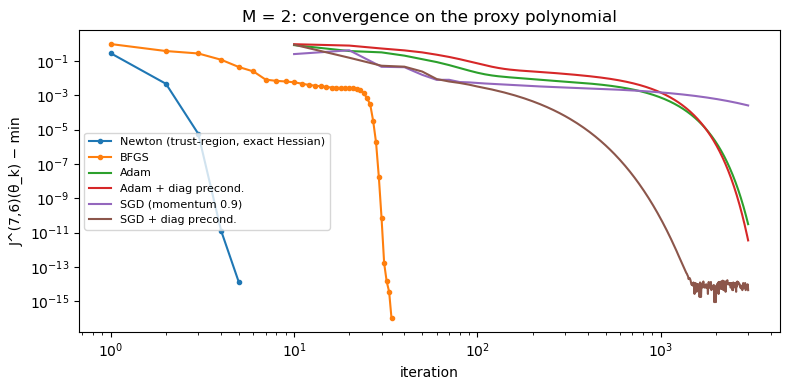

  Newton (trust-region, exact Hessian): J = 3.78076336   |∇J| = 2.2e-11   λ_min(∇²J) = 2.18e-03   (0.03s)
                                  BFGS: J = 3.78076336   |∇J| = 8.6e-09   λ_min(∇²J) = 2.18e-03   (0.07s)
                                  Adam: J = 3.78076336   |∇J| = 4.3e-07   λ_min(∇²J) = 2.18e-03   (3.35s)
                  Adam + diag precond.: J = 3.78076336   |∇J| = 2.4e-07   λ_min(∇²J) = 2.18e-03   (3.37s)
                    SGD (momentum 0.9): J = 3.78102028   |∇J| = 1.1e-03   λ_min(∇²J) = 2.18e-03   (3.92s)
                   SGD + diag precond.: J = 3.78076336   |∇J| = 6.5e-15   λ_min(∇²J) = 2.18e-03   (3.97s)

θ*(M=2, L1=7, L2=6): {'∅': -1.5229, '1': 1.8094, '2': -0.1366, '11': -1.024, '12': -0.9379, '21': 0.352, '22': 0.0041}
multi-start (30 random starts, scale 3): 1 distinct local minimiser(s), values [3.780763]
boundedness probe on 2000 random rays (|θ| ≤ 30): smallest value 3.977; rays with J < 0 at |θ| = 30: 0


In [16]:
runs = {"Newton (trust-region, exact Hessian)": dict(method='newton'),
        "BFGS": dict(method='bfgs'),
        "Adam": dict(method='adam', lr=0.05, n_iter=3000),
        "Adam + diag precond.": dict(method='adam', lr=0.05, n_iter=3000, precondition='diag'),
        "SGD (momentum 0.9)": dict(method='sgd', lr=0.02, n_iter=3000),
        "SGD + diag precond.": dict(method='sgd', lr=0.2, n_iter=3000, precondition='diag')}
res2 = {k: minimise_poly(J2, **kw) for k, kw in runs.items()}
best = min(r['value'] for r in res2.values())
fig, ax = plt.subplots(figsize=(8, 4))
for k, r in res2.items():
    h = r['history']
    if len(h['it']): ax.semilogy(h['it'], np.maximum(h['value'] - best, 1e-16), 'o-' if len(h['it']) < 50 else '-', ms=3, label=k)
ax.set_xscale('log'); ax.set_xlabel("iteration"); ax.set_ylabel("J^(7,6)(θ_k) − min"); ax.legend(fontsize=8)
ax.set_title("M = 2: convergence on the proxy polynomial"); plt.tight_layout(); plt.show()
for k, r in res2.items():
    print(f"{k:>38}: J = {r['value']:.8f}   |∇J| = {r['grad_norm']:.1e}   λ_min(∇²J) = {r['hess_min_eig']:.2e}   ({r['time']:.2f}s)")
th2 = res2["Newton (trust-region, exact Hessian)"]['theta']
print("\nθ*(M=2, L1=7, L2=6):", {("∅" if not w else TensorSpace.word_str(w)): round(float(x), 4) for w, x in zip(sols[2]['words'], th2)})
rng = np.random.default_rng(0); found = []
for _ in range(30):
    r = minimise_poly(J2, 'newton', theta0=3 * rng.normal(size=J2.P))
    if r['grad_norm'] < 1e-6 and r['hess_min_eig'] > 0 and not any(np.abs(r['theta'] - f).max() < 1e-5 for f in found):
        found.append(r['theta'])
print(f"multi-start (30 random starts, scale 3): {len(found)} distinct local minimiser(s), values {[round(J2(f), 6) for f in found]}")
neg = 0; lo = np.inf
for _ in range(2000):
    dvec = rng.normal(size=J2.P); dvec /= np.linalg.norm(dvec)
    vals = [J2(R * dvec) for R in (1, 3, 10, 30)]; lo = min(lo, min(vals)); neg += vals[-1] < 0
print(f"boundedness probe on 2000 random rays (|θ| ≤ 30): smallest value {lo:.3f}; rays with J < 0 at |θ| = 30: {neg}")

Newton, BFGS, both Adam runs and preconditioned SGD reach the same point to eight digits; plain momentum-SGD is still about $3\times10^{-4}$ away after 3,000 iterations. The Hessian there is positive definite, and the multi-start finds no other local minimum, so for $M=2$ the proxy behaves like a strictly convex function near its minimiser.
The random-ray probe finds no direction in which it becomes negative. This is evidence, not a proof, that the polynomial is bounded below.

The Hessian is badly conditioned: signature coordinates such as $t$, $t^2/2$ and $\int Y\,dt$ are strongly correlated. As in the previous notebook, the first-order methods need many iterations for the last digits; Newton needs a handful.

## 8. Prompt 3: truncation levels $(\mathrm L_1,\mathrm L_2,M)$ against the benchmark

For each $(\mathrm L_1,\mathrm L_2)$ and $M\in\{0,1,2,3\}$ we minimise the proxy with Newton from $\theta=0$. Each resulting control is then evaluated by Monte Carlo on the **true closed-loop system**, with 20,000 paths and 500 steps. Every control shares the same $(B,W)$ noise with the Kalman–Riccati benchmark, and we report the paired excess cost $J(u^{\rm L_1,L_2,M})-J(u^*)$ and the $L^2(d\mathbb P\otimes dt)$ distance to $u^*$.

$\mathrm L_1\le7$ is the practical limit here: the pairing matrices for three letters need $\mathbb E[\widehat{\mathbb W}_T]$ up to level $2\mathrm L_1+1$, and $3^{15}$ entries is about the memory budget.

In [17]:
pairs = [(2, 1), (3, 2), (4, 3), (5, 4), (6, 5), (7, 6), (7, 7)]
Ms = [0, 1, 2, 3]
fits = {}
for (L1, L2) in pairs:
    Fp = F76 if (L1, L2) == (7, 6) else CostFunctionals(2, m.T, L1, L2, m.m_max)
    for Mx in Ms:
        Jp = proxy_cost(m, sols[Mx], L1, L2, Fp)
        r = minimise_poly(Jp, 'newton')
        fits[(Mx, L1, L2)] = dict(theta=r['theta'], proxy=r['value'], terms=Jp.codes.size, degree=Jp.degree,
                                  unid=len(r['inactive']), hess_min=r['hess_min_eig'])
    if Fp is not F76: del Fp; gc.collect()
t0 = time.perf_counter()
ev = evaluate_partial(m, {k: (v['theta'], k[0]) for k, v in fits.items()}, n_paths=20000, n_steps=500, seed=1)
print(f"Monte Carlo evaluation of {len(fits)} controls: {time.perf_counter() - t0:.0f}s")
c_star = ev["u* (Kalman–Riccati)"]['cost']
print(f"\nJ* = {bench['J']:.4f} (exact), {mean_ci(c_star)[0]:.4f} ± {mean_ci(c_star)[1]:.4f} (MC, 500 steps);  full information: {bench['J_full']:.4f}\n")
print(f"{'M':>2} {'L1':>3} {'L2':>3} | {'terms':>6} {'deg':>3} {'unid.':>5} | {'min J^(L1,L2)':>13} | {'true cost (MC)':>17} | {'excess over u*':>17} | L2 to u*")
for k, v in fits.items():
    e_ = ev[k]; mu, ci = mean_ci(e_['cost']); dm, dc = mean_ci(e_['diff'])
    print(f"{k[0]:>2} {k[1]:>3} {k[2]:>3} | {v['terms']:>6} {v['degree']:>3} {v['unid']:>5} | {v['proxy']:13.4f} | {mu:8.4f} ± {ci:.4f} | {dm:+8.4f} ± {dc:.4f} | {e_['L2']:.3f}")
print("(unid. = coefficients that do not occur in the proxy and are kept at 0)")

Monte Carlo evaluation of 28 controls: 97s

J* = 3.7778 (exact), 3.7915 ± 0.0477 (MC, 500 steps);  full information: 2.8649

 M  L1  L2 |  terms deg unid. | min J^(L1,L2) |    true cost (MC) |    excess over u* | L2 to u*
 0   2   1 |      3   2     0 |        3.9348 |   4.0879 ± 0.0536 |  +0.2964 ± 0.0105 | 0.467
 1   2   1 |     10   2     0 |        3.7226 |   4.0043 ± 0.0541 |  +0.2128 ± 0.0107 | 0.371
 2   2   1 |     10   2     4 |        3.7226 |   4.0043 ± 0.0541 |  +0.2128 ± 0.0107 | 0.371
 3   2   1 |     10   2    12 |        3.7226 |   4.0043 ± 0.0541 |  +0.2128 ± 0.0107 | 0.371
 0   3   2 |      3   2     0 |        4.0587 |   4.0879 ± 0.0536 |  +0.2964 ± 0.0105 | 0.467
 1   3   2 |     14   4     0 |        3.8644 |   3.8674 ± 0.0502 |  +0.0758 ± 0.0062 | 0.228
 2   3   2 |     44   4     0 |        3.5344 |   4.1595 ± 0.0527 |  +0.3680 ± 0.0115 | 0.534
 3   3   2 |     44   4     8 |        3.5344 |   4.1595 ± 0.0527 |  +0.3680 ± 0.0115 | 0.534
 0   4   3 |      3   2   

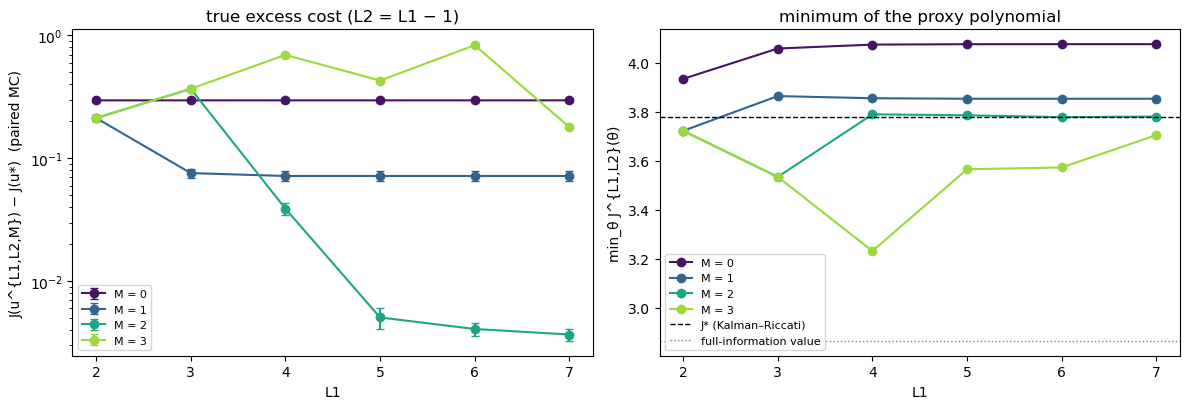

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
L1s = [p[0] for p in pairs[:-1]]
for Mx, col in zip(Ms, plt.cm.viridis(np.linspace(0.05, 0.85, len(Ms)))):
    keys = [(Mx, L1, L1 - 1) for L1 in L1s]
    mu = np.array([mean_ci(ev[k]['diff'])[0] for k in keys]); ci = np.array([mean_ci(ev[k]['diff'])[1] for k in keys])
    ax[0].errorbar(L1s, np.maximum(mu, 1e-4), yerr=ci, marker='o', capsize=3, color=col, label=f"M = {Mx}")
    ax[1].plot(L1s, [fits[k]['proxy'] for k in keys], 'o-', color=col, label=f"M = {Mx}")
ax[0].set_yscale('log'); ax[0].set_ylabel("J(u^{L1,L2,M}) − J(u*)  (paired MC)"); ax[0].set_title("true excess cost (L2 = L1 − 1)")
ax[1].axhline(bench['J'], color='k', ls='--', lw=1, label="J* (Kalman–Riccati)")
ax[1].axhline(bench['J_full'], color='0.5', ls=':', lw=1, label="full-information value")
ax[1].set_ylabel("min_θ J^{L1,L2}(θ)"); ax[1].set_title("minimum of the proxy polynomial")
for a in ax: a.set_xlabel("L1"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading the results.**
* $M=0$ is a constant control and ignores the observations. Its proxy is exactly quadratic, and it settles at the best constant control.
* $M=1$ and $M=2$ converge in $\mathrm L_1$. For $M=2$ the true excess cost over $J^*$ falls to a few thousandths, about 0.1% of $J^*$, at $(\mathrm L_1,\mathrm L_2)=(7,6)$, and the control is close to $u^*$ in $L^2$.
* $M=3$ shows the ordered limit "$\mathrm L\gg M$" of the paper in a sharper form. At $\mathrm L_1\le7$ the proxy minimum falls **below** $J^*$, which is impossible for a true cost. The minimiser exploits truncation error with large coefficients, and the true cost of the resulting control is poor. Going further needs larger $\mathrm L_1$, or a method without truncation (below).

**Effect of $\mathrm L_2$.** At fixed $\mathrm L_1=7$ with $M=2$, a small $\mathrm L_2$ truncates the control-effort term $B\,\tilde{\mathtt u}⧢\tilde{\mathtt u}$. Control then looks cheaper than it is, and the proxy minimum is again spuriously low. $\mathrm L_2$ should be close to $\mathrm L_1$.

In [19]:
print(f"{'L2':>3} | {'min J^(7,L2)':>12} | max|θ|")
for L2 in range(1, 8):
    Fl = F76 if L2 == 6 else CostFunctionals(2, m.T, 7, L2, m.m_max)
    r = minimise_poly(proxy_cost(m, sols[2], 7, L2, Fl), 'newton')
    print(f"{L2:>3} | {r['value']:12.5f} | {np.abs(r['theta']).max():.2f}")
    if Fl is not F76: del Fl; gc.collect()

 L2 | min J^(7,L2) | max|θ|
  1 |      2.62066 | 5.28
  2 |      3.73896 | 7.26
  3 |      3.43443 | 14.43
  4 |      3.78438 | 1.43
  5 |      3.78119 | 1.77
  6 |      3.78076 | 1.81
  7 |      3.78022 | 1.83


### Stochastic gradients of the true closed-loop cost ("or else")

The truncation is avoidable altogether. Simulate the closed loop and differentiate the pathwise cost exactly by forward-mode sensitivities, propagating $\partial X/\partial\theta$ and $\partial\widehat{\mathbb Y}/\partial\theta$. Here $\theta$ moves $X$, $X$ moves $Y$, and $Y$ moves its signature through Chen's identity (`chen_step_dual`). Adam then runs on fresh minibatches; this is the `mc_sde` mode of the previous notebook, now with the nonlinear observation feedback.
It needs neither $\mathbb E[\widehat{\mathbb W}_T]$ nor the tensors $\mathtt X$, $\tilde{\mathtt u}$. Here it is warm-started from the polynomial minimiser, so the two methods are used together.

In [20]:
def chen_step_dual(S, dS, inc, dinc):
    """Chen step and its forward-mode derivative.  S: list of (n, d^m); dS: list of (n, P, d^m);
    inc: (n, d); dinc: (n, P, d) = ∂inc/∂θ.  Same Horner recursion as chen_step, differentiated term by term."""
    n = inc.shape[0]; P = dinc.shape[1]; new, dnew = [S[0]], [dS[0]]
    for mlev in range(1, len(S)):
        acc = S[0] * inc / mlev
        dacc = (dS[0] * inc[:, None, :] + S[0][:, :, None] * dinc) / mlev
        for j in range(1, mlev):
            a, da = acc + S[j], dacc + dS[j]
            acc = (a[:, :, None] * inc[:, None, :]).reshape(n, -1) / (mlev - j)
            dacc = (da[:, :, :, None] * inc[:, None, None, :] + a[:, None, :, None] * dinc[:, :, None, :]).reshape(n, P, -1) / (mlev - j)
        new.append(S[mlev] + acc); dnew.append(dS[mlev] + dacc)
    return new, dnew


def closed_loop_cost_grad(model, theta, M, dB, dW, dt):
    """Mean pathwise cost of u = <θ, Ŷ^{≤M}> on the given increments and its exact θ-gradient (forward-mode
    sensitivities of X and of the observation signature: θ moves X, X moves Y, Y moves Ŷ).  No truncation in L."""
    m = model; n, steps = dB.shape; P = len(theta); th = np.asarray(theta, float)
    X = np.full(n, float(m.X0)); dX = np.zeros((n, P)); cost = np.zeros(n); dcost = np.zeros((n, P))
    S = [np.ones((n, 1))] + [np.zeros((n, 2 ** k)) for k in range(1, M + 1)]
    dS = [np.zeros((n, P, 2 ** k)) for k in range(M + 1)]
    for i in range(steps):
        t = i * dt
        At, Bt, Ct, Dt = m.poly(m.A, t), m.poly(m.B, t), m.poly(m.C, t), m.poly(m.D, t)
        Sf = np.concatenate(S, axis=1); dSf = np.concatenate(dS, axis=2)
        u = Sf @ th; du = dSf @ th + Sf                                      # (n,), (n, P)
        cost += dt * (At * X ** 2 + Bt * u ** 2 + 2 * Ct * X + 2 * Dt * u)
        dcost += dt * ((2 * At * X + 2 * Ct)[:, None] * dX + (2 * Bt * u + 2 * Dt)[:, None] * du)
        dYi = (m.c0 + m.c1 * X) * dt + dW[:, i]
        inc = np.c_[np.full(n, dt), dYi]; dinc = np.zeros((n, P, 2)); dinc[:, :, 1] = m.c1 * dt * dX
        S, dS = chen_step_dual(S, dS, inc, dinc)
        X, dX = X + (m.b0 + m.b1 * X + m.b2 * u) * dt + dB[:, i], dX + (m.b1 * dX + m.b2 * du) * dt
    cost += m.E * X ** 2 + 2 * m.G * X; dcost += (2 * m.E * X + 2 * m.G)[:, None] * dX
    return cost.mean(), dcost.mean(0)


def optimise_mc(model, M, theta0=None, n_iter=1000, lr=0.02, batch_size=256, n_steps=100, betas=(0.9, 0.999),
                eps=1e-8, lr_decay=None, average_tail=0.25, seed=0, record_every=25, method='adam', momentum=0.9):
    """Adam / SGD on fresh Monte-Carlo minibatches of the *true* closed-loop cost (mode 'mc_sde' of the previous
    notebook, now with the nonlinear observation feedback).  Unbiased for the Euler-discretised J(θ); needs neither
    the expected signature nor the tensors 𝚇̃, ũ.  Returns Polyak–Ruppert averaged iterates."""
    rng = np.random.default_rng(seed); dt = model.T / n_steps; P = 2 ** (M + 1) - 1
    th = np.zeros(P) if theta0 is None else np.array(theta0, float)
    m1, m2, vel = np.zeros(P), np.zeros(P), np.zeros(P); avg = np.zeros(P); n_avg = 0
    start_avg = int((1 - average_tail) * n_iter); hist = dict(it=[], value=[]); t0 = time.perf_counter()
    for k in range(1, n_iter + 1):
        dB = rng.normal(scale=np.sqrt(dt), size=(batch_size, n_steps)); dW = rng.normal(scale=np.sqrt(dt), size=(batch_size, n_steps))
        val, g = closed_loop_cost_grad(model, th, M, dB, dW, dt)
        step = lr * (lr_decay(k) if lr_decay else 1.0)
        if method == 'adam':
            m1 = betas[0] * m1 + (1 - betas[0]) * g; m2 = betas[1] * m2 + (1 - betas[1]) * g * g
            th = th - step * (m1 / (1 - betas[0] ** k)) / (np.sqrt(m2 / (1 - betas[1] ** k)) + eps)
        else:
            vel = momentum * vel - step * g; th = th + vel
        if k > start_avg: n_avg += 1; avg += (th - avg) / n_avg
        if k % record_every == 0: hist['it'].append(k); hist['value'].append(val)
    return dict(theta=avg if n_avg else th, theta_last=th, time=time.perf_counter() - t0,
                history={k: np.array(v) for k, v in hist.items()}, method=method + ' (mc_sde)')

In [21]:
# gradient check of the pathwise cost
rng = np.random.default_rng(0); nn, st = 64, 60; dtt = m.T / st
dBc = rng.normal(scale=np.sqrt(dtt), size=(nn, st)); dWc = rng.normal(scale=np.sqrt(dtt), size=(nn, st))
thc = rng.normal(size=15) * 0.3; v_, g_ = closed_loop_cost_grad(m, thc, 3, dBc, dWc, dtt); I15 = np.eye(15)
fd = np.array([(closed_loop_cost_grad(m, thc + 1e-6 * I15[i], 3, dBc, dWc, dtt)[0]
                - closed_loop_cost_grad(m, thc - 1e-6 * I15[i], 3, dBc, dWc, dtt)[0]) / 2e-6 for i in range(15)])
print(f"pathwise gradient vs finite differences: max error {np.abs(g_ - fd).max():.1e} (|∇| ≈ {np.abs(g_).max():.1f})")

decay = lambda k: 1 / (1 + k / 400)
mc_runs = {
    "Adam mc_sde, M = 2, warm start (poly 7,6)": (2, dict(theta0=fits[(2, 7, 6)]['theta'], n_iter=1000, lr=0.01)),
    "Adam mc_sde, M = 2, cold start (θ = 0)":     (2, dict(n_iter=1000, lr=0.05)),
    "Adam mc_sde, M = 3, warm start (poly M=2)": (3, dict(theta0=np.r_[fits[(2, 7, 6)]['theta'], np.zeros(8)], n_iter=800, lr=0.01)),
}
mc_res = {}
for k, (Mx, kw) in mc_runs.items():
    mc_res[k] = (optimise_mc(m, Mx, lr_decay=decay, batch_size=256, n_steps=100, seed=7, **kw), Mx)
    print(f"{k}: {mc_res[k][0]['time']:.0f}s")
ctrl_mc = {"poly M=2 (7,6)": (fits[(2, 7, 6)]['theta'], 2), "poly M=3 (7,6)": (fits[(3, 7, 6)]['theta'], 3)}
ctrl_mc.update({k: (r['theta'], Mx) for k, (r, Mx) in mc_res.items()})
ev_mc = evaluate_partial(m, ctrl_mc, n_paths=20000, n_steps=500, seed=1)
print(f"\n{'control':>44} | {'true cost (MC)':>17} | {'excess over u*':>17} | L2 to u*")
for k, v in ev_mc.items():
    mu, ci = mean_ci(v['cost']); dm, dc = mean_ci(v['diff'])
    print(f"{k:>44} | {mu:8.4f} ± {ci:.4f} | {dm:+8.4f} ± {dc:.4f} | {v['L2']:.3f}")

pathwise gradient vs finite differences: max error 1.8e-09 (|∇| ≈ 7.1)
Adam mc_sde, M = 2, warm start (poly 7,6): 64s
Adam mc_sde, M = 2, cold start (θ = 0): 66s
Adam mc_sde, M = 3, warm start (poly M=2): 219s

                                     control |    true cost (MC) |    excess over u* | L2 to u*
                         u* (Kalman–Riccati) |   3.7915 ± 0.0477 |  +0.0000 ± 0.0000 | 0.000
                              poly M=2 (7,6) |   3.7952 ± 0.0478 |  +0.0037 ± 0.0004 | 0.060
                              poly M=3 (7,6) |   3.9711 ± 0.0457 |  +0.1795 ± 0.0074 | 0.377
   Adam mc_sde, M = 2, warm start (poly 7,6) |   3.7956 ± 0.0480 |  +0.0041 ± 0.0006 | 0.060
      Adam mc_sde, M = 2, cold start (θ = 0) |   3.7998 ± 0.0481 |  +0.0083 ± 0.0006 | 0.087
   Adam mc_sde, M = 3, warm start (poly M=2) |   3.7932 ± 0.0479 |  +0.0017 ± 0.0006 | 0.039


The stochastic method confirms the polynomial solution for $M=2$: started there, it stays there. For $M=3$, where the truncated proxy misleads, it reaches a better control than any $M=2$ control. Started from $\theta=0$ it is slower, and 1,000 noisy iterations leave it short of the warm-started result. The two methods are complementary:
* the polynomial gives an exact, cheap, deterministic objective and a good starting point;
* the stochastic gradients remove the truncation bias once $M$ is too large for the available $\mathrm L$.

## 9. Prompt 4: sample paths

Every control below is driven by **the same** $(B,W)$ noise. The top panel shows the hidden state $X$; the dashed black line is the Kalman filter $\hat X$ of the benchmark. The middle panel shows the observation $Y$, which differs between controls because it depends on $X$. The bottom panel shows the control $u$.
The benchmark is in black and the signature controls in colour. The legend gives each control's cost on the plotted path; on a single path a control can beat $u^*$, which is optimal only on average.

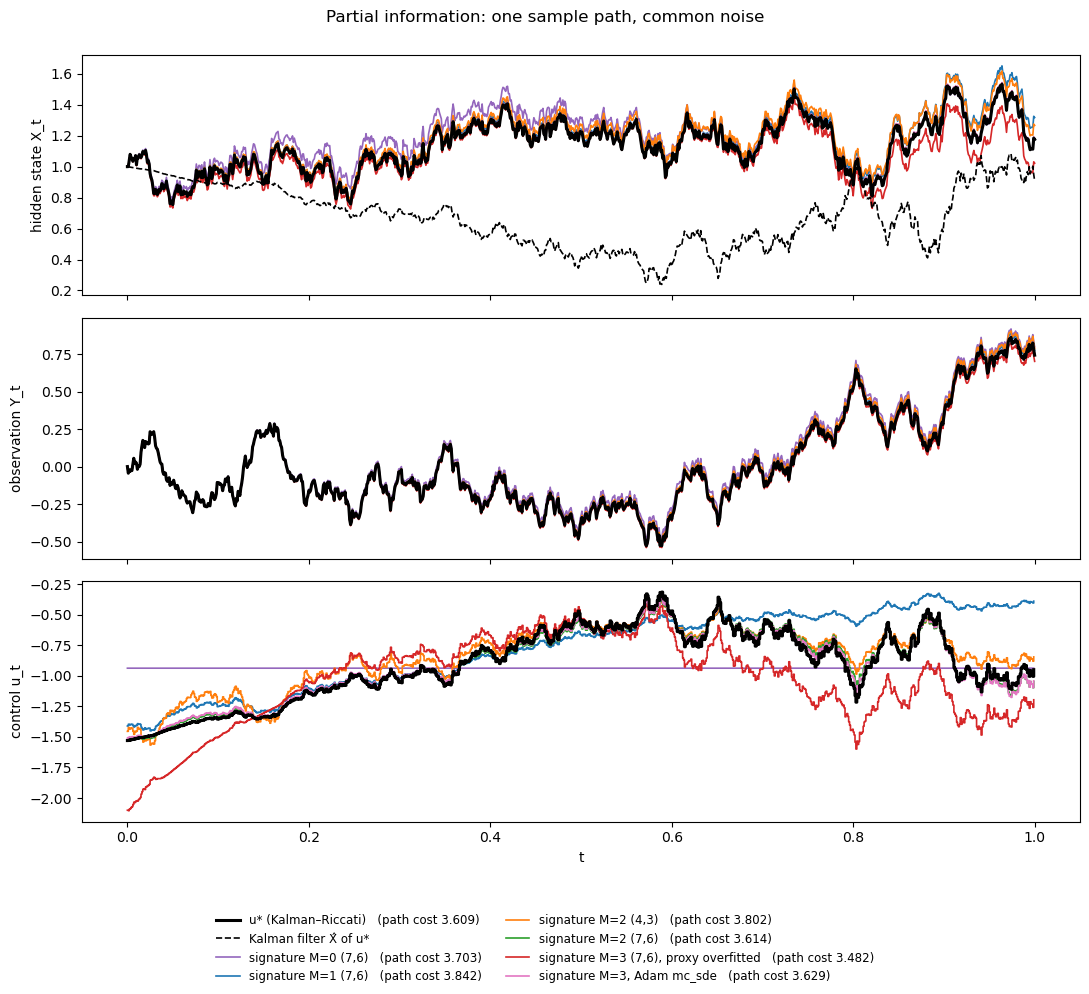

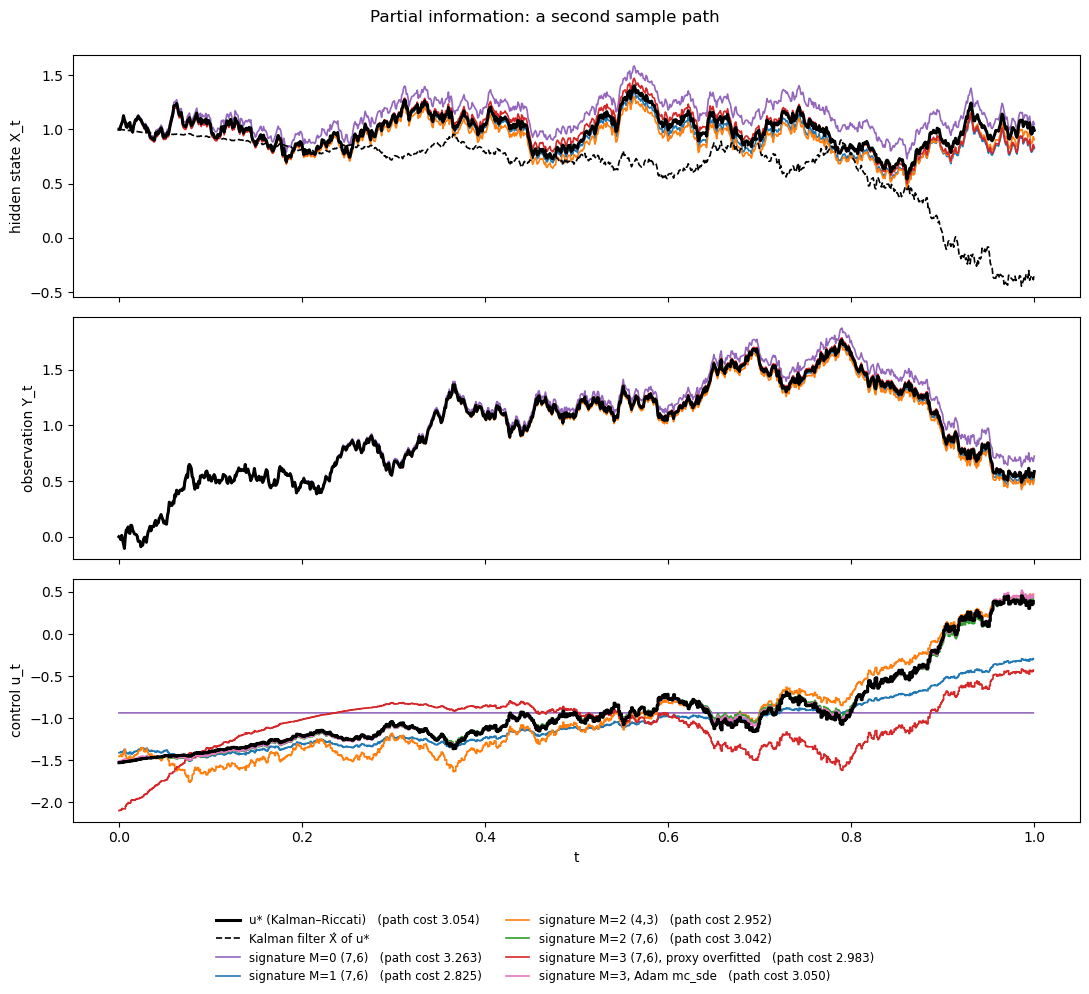

In [22]:
def compare_partial_paths(model, controls, n_steps=1000, seed=11, path=0, title=""):
    rng = np.random.default_rng(seed); dt = model.T / n_steps
    dB = rng.normal(scale=np.sqrt(dt), size=(3, n_steps)); dW = rng.normal(scale=np.sqrt(dt), size=(3, n_steps))
    ref = simulate_partial(model, dB, dW, dt, None, 'kalman', bench=kalman_riccati_benchmark(model, n_grid=n_steps + 1))
    sims = {k: simulate_partial(model, dB, dW, dt, th, 'signature', M=Mx) for k, (th, Mx) in controls.items()}
    tg = np.linspace(0, model.T, n_steps + 1)
    fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
    h = [ax[0].plot(tg, ref['X'][:, path], color='black', lw=2.2, zorder=5,
                    label=f"u* (Kalman–Riccati)   (path cost {ref['cost'][path]:.3f})")[0]]
    h.append(ax[0].plot(tg, ref['Xhat'][:, path], color='black', lw=1.2, ls='--', zorder=5, label="Kalman filter X̂ of u*")[0])
    ax[1].plot(tg, ref['Y'][:, path], color='black', lw=2.2, zorder=5)
    ax[2].plot(tg[:-1], ref['U'][:, path], color='black', lw=2.2, drawstyle='steps-post', zorder=5)
    cols = [plt.cm.tab10(i) for i in (4, 0, 1, 2, 3, 6, 8, 9)][:len(sims)]
    for (k, s), c in zip(sims.items(), cols):
        h.append(ax[0].plot(tg, s['X'][:, path], color=c, lw=1.2, label=f"{k}   (path cost {s['cost'][path]:.3f})")[0])
        ax[1].plot(tg, s['Y'][:, path], color=c, lw=1.2)
        ax[2].plot(tg[:-1], s['U'][:, path], color=c, lw=1.2, drawstyle='steps-post')
    for a, lab in zip(ax, ["hidden state X_t", "observation Y_t", "control u_t"]):
        a.set_ylabel(lab)
    ax[2].set_xlabel("t"); fig.suptitle(title)
    fig.legend(handles=h, loc='lower center', ncol=2, fontsize=8.5, frameon=False)
    plt.tight_layout(rect=(0, 0.11, 1, 0.98)); plt.show()

ctrls_plot = {"signature M=0 (7,6)": (fits[(0, 7, 6)]['theta'], 0),
              "signature M=1 (7,6)": (fits[(1, 7, 6)]['theta'], 1),
              "signature M=2 (4,3)": (fits[(2, 4, 3)]['theta'], 2),
              "signature M=2 (7,6)": (fits[(2, 7, 6)]['theta'], 2),
              "signature M=3 (7,6), proxy overfitted": (fits[(3, 7, 6)]['theta'], 3),
              "signature M=3, Adam mc_sde": (mc_res["Adam mc_sde, M = 3, warm start (poly M=2)"][0]['theta'], 3)}
compare_partial_paths(m, ctrls_plot, seed=11, title="Partial information: one sample path, common noise")
compare_partial_paths(m, ctrls_plot, seed=12, title="Partial information: a second sample path")

The well-resolved signature controls ($M=2$ at $(7,6)$, and $M=3$ from the stochastic method) track $u^*$ closely. Through the signature of $Y$ they effectively reproduce the Kalman filter's response to the observations.
* The constant control ($M=0$) and the $M=1$ control ($u^\phi+u^{\mathbf 1}t+u^{\mathbf 2}(Y_t-Y_0)$) react weakly or too simply.
* The $M=3$ control from the $(7,6)$ proxy is visibly off: its coefficients fit truncation error rather than the problem (true excess about $0.18$; the $(7,7)$ proxy control in the table is far worse and is left out of the plots so that it does not dominate the scale).

## 10. Remarks

* **Structure of the proxy.** For $M\ge1$ the cost is a genuine polynomial in $\theta$, but a small one. Its degree grows like $\mathrm L_1$ (about $\lceil\mathrm L_1/2\rceil$ per factor of $\mathtt X$), because the feedback loop $X\to Y\to u\to X$ costs two tensor levels. For $M\le2$ and $\mathrm L_1\le7$ it has at most about a thousand terms.
  The coefficients are computed exactly: tensor-valued polynomials, the shuffles of the previous notebook, and pairing matrices. Newton with the exact Hessian minimises them in milliseconds.
* **Local, not global.** For $M=2$ we found a unique, strictly convex local minimum (multi-start), and no evidence of unboundedness. Neither is guaranteed in general, so the notebook reports $\lambda_{\min}(\nabla^2J)$ at every solution.
* **Ordered limits.** The proxy is reliable only when $\mathrm L_1$ is large relative to $M$ and $\mathrm L_2\approx\mathrm L_1$. Otherwise the minimiser exploits truncation error, and its proxy value can fall below $J^*$. A proxy value below $J^*$, or below the full-information bound, is a quick red flag.
* **Two complementary optimisers.**
  * The exact polynomial: deterministic, cheap, with exact derivatives, but limited by $\mathrm L_1\le7$ here.
  * Stochastic gradients of the true closed-loop cost: no truncation, but noisy and slower. Warm-starting the second from the first worked best.
* **Generalisation.** The note's toy model is 1-D, so the code is written for $N=K=1$ and one observation. The recursion only uses the operations of the multi-dimensional notebook (letter concatenation, shuffles, pairing matrices), so the extension is mechanical. $\tilde{\mathtt Y}(\mathbf v)$ would then be indexed by words over $\{t,Y^{(1)},\dots\}$, and $X$ by $n$.